In [1]:
# Here we want to set up a reference signal and an input signal which on interfering produce three intensity distributions - one with zero phase difference at the centre and the other two on either sides.

In [43]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib.colors import LogNorm
from matplotlib import cm
import scipy.ndimage
from scipy.ndimage import gaussian_filter, correlate

#Creating the fields

In [44]:
#Mesh
Nx = 600
Ny = 400
X = np.linspace(0, 1, num=Nx)
Y = np.linspace(0,1, num=Ny)
xv, yv = np.meshgrid(X, Y)

[[     0      1      2 ...    597    598    599]
 [   600    601    602 ...   1197   1198   1199]
 [  1200   1201   1202 ...   1797   1798   1799]
 ...
 [238200 238201 238202 ... 238797 238798 238799]
 [238800 238801 238802 ... 239397 239398 239399]
 [239400 239401 239402 ... 239997 239998 239999]]
[[   -54591    -54673    -54816 ...   -139901   -140044   -140196]
 [  -144591   -144673   -144816 ...   -229901   -230044   -230196]
 [  -230391   -230473   -230616 ...   -315701   -315844   -315996]
 ...
 [-34121391 -34121473 -34121616 ... -34206701 -34206844 -34206996]
 [-34207191 -34207273 -34207416 ... -34292501 -34292644 -34292796]
 [-34238391 -34238473 -34238616 ... -34323701 -34323844 -34323996]]


Text(0.5, 1.0, 'Absolute value of the signal')

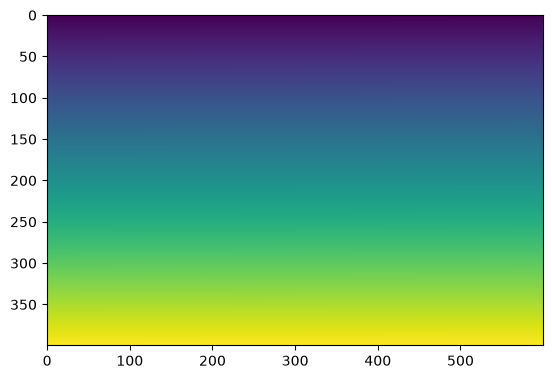

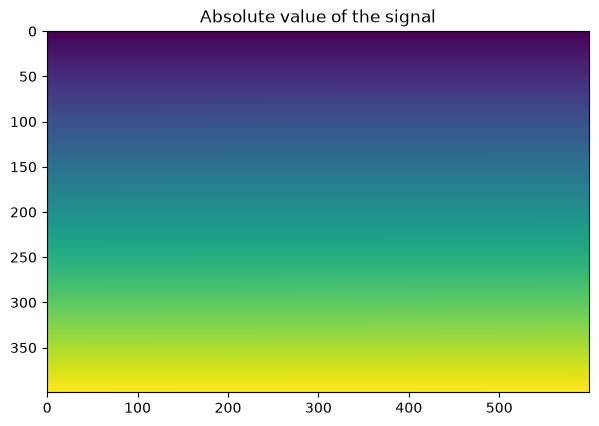

In [35]:
#Trying different signals for reconstruction
input_img=np.arange(240000).reshape(400,600) #arranges 25 points into a 5x5 matrix
plt.imshow(input_img)
print(input_img)
weights = [[0,-1,8],
           [-61,1,1],
           [0,-91,0]]
image_sig = scipy.ndimage.correlate(input_img, weights)
# image_sig = image_sig/np.abs(image_sig)
print(image_sig)
plt.figure(figsize = (7,10))
plt.imshow(abs(image_sig))
plt.title('Absolute value of the signal')

Text(0.5, 1.0, 'Absolute value of the signal')

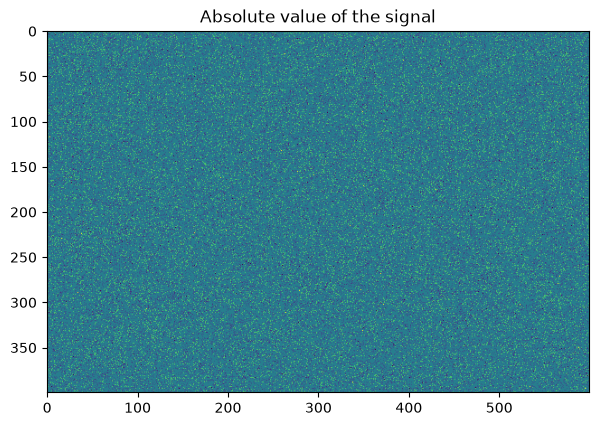

In [45]:
#Complex image to reconstruct
grainSize = 20;
temp  = np.random.rand(Ny,Nx)-.5+np.random.rand(Ny,Nx)*1j-0.5j
image_sig = scipy.ndimage.gaussian_filter(temp.real, grainSize/2)+1j*scipy.ndimage.gaussian_filter(temp.imag, grainSize/2)
image_sig = image_sig/np.abs(image_sig)
plt.figure(figsize = (7,10))
plt.imshow(abs(image_sig))
plt.title('Absolute value of the signal')

Reference Image Construction which will be tilted by an angle theta wrt the complex field

Text(0.5, 1.0, 'Absolute value of the reference')

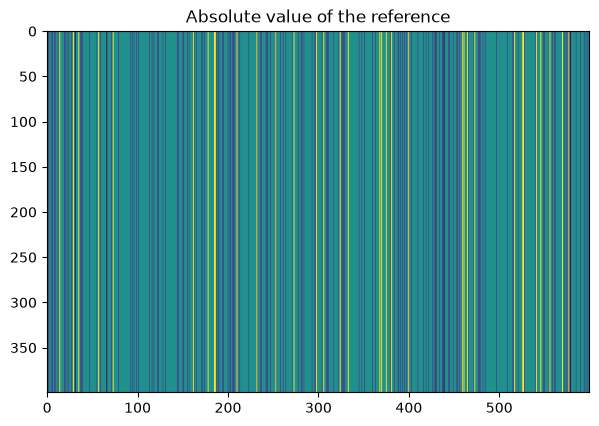

In [46]:

kx = 400
image_ref = np.exp(1j*xv*kx)
plt.figure(figsize = (7,10))
plt.imshow(abs(image_ref))
plt.title('Absolute value of the reference')

In [47]:
I = np.abs(image_ref+image_sig)**2;

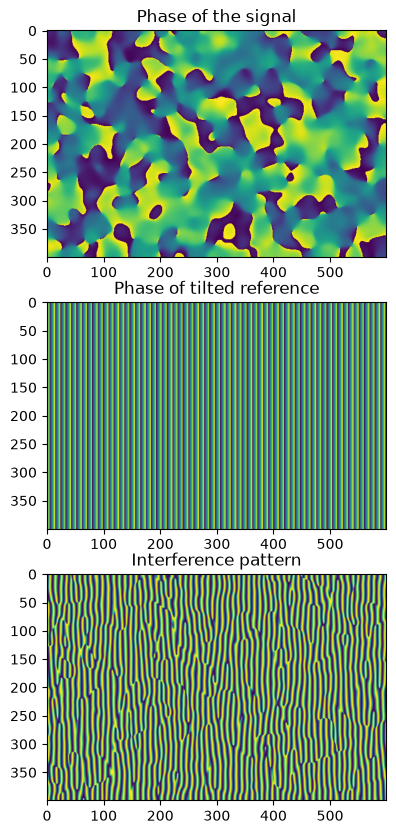

In [48]:
plt.figure(figsize = (7,10))
plt.subplot(311)
plt.imshow(np.angle(image_sig))
plt.title('Phase of the signal')
plt.subplot(312)
plt.imshow(np.angle(image_ref))
plt.title('Phase of tilted reference')
plt.subplot(313)
plt.imshow(I)
plt.title('Interference pattern')
plt.show()

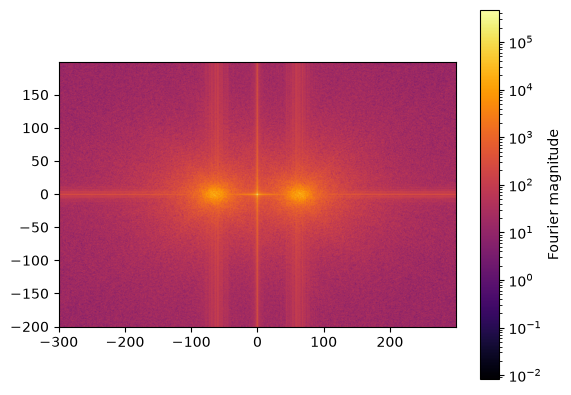

In [49]:
from matplotlib.colors import LogNorm
nb = 5; 
Fh = np.fft.fftshift(np.fft.fft2(I,s=[Ny*nb, Nx*nb]))

plt.figure()

magnitude = np.abs(Fh)

plt.imshow(
    magnitude + 1e-10,
    extent=[
        -0.5 * Nx,
        0.5 * Nx - 1,
        -0.5 * Ny,
        0.5 * Ny - 1
    ],
    
    origin='lower',
    cmap='inferno',
    norm=LogNorm()
)

plt.colorbar(label='Fourier magnitude')
plt.show()

In [50]:
## Create the vector of the spatial frequencies
SfreqX = np.arange(-0.5*Nx,0.5*Nx,1/nb)
SfreqY = np.arange(-0.5*Ny,0.5*Ny,1/nb)

## Frequency grid
[Sx,Sy] = np.meshgrid(SfreqX,SfreqY)

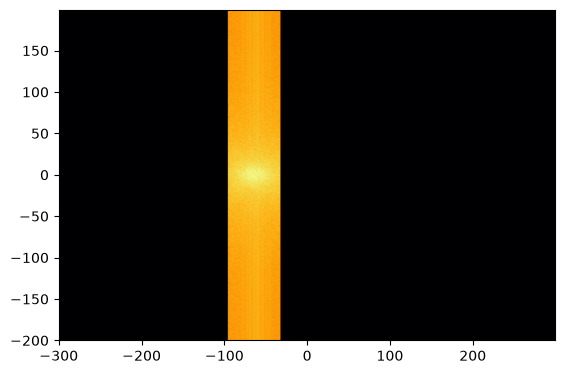

In [51]:
## Now we want to do a filtering of the spatial frequencies to keep only the
## -1 order
freq = kx/(2*np.pi)        # center frequency of the first orders
width = freq               # width of the filtering window

## First create the mask, we want to conseve the spatial frequencies around minus the carrier frequency ('-freq') with a window of size 'width'
Mask1 = (Sx > -freq-width/2)*(Sx < -freq+width/2)

## We get the field in the Fourier plane after filtering
Fh2 = Fh*Mask1

magnitude = np.abs(Fh2)

## Display it
plt.figure()
plt.imshow(
    magnitude + 1e-10,
    extent=[
        -0.5 * Nx,
        0.5 * Nx - 1,
        -0.5 * Ny,
        0.5 * Ny - 1
    ],
    
    origin='lower',
    cmap='inferno',
    norm=LogNorm()
)
plt.show()

<Figure size 640x480 with 0 Axes>

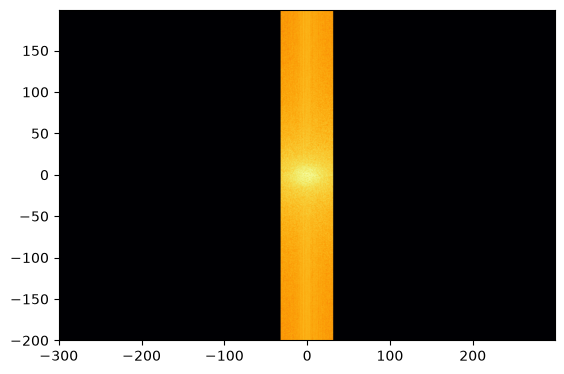

In [41]:
## We shift the spatial frequencies around zero to remove the effect of the angular tilt due to -1 order
#Mask2 = (Sx > -width/2)*(Sx < width/2)  # window centered around 0 of width 'width' 
I1 = np.nonzero(Mask1)                  # gets the indices corresponding to Mask1
Fh3 = np.zeros(Fh.shape)+np.zeros(Fh.shape)*1j
# We copy the -1 order centered to the zero frequency
Fh3[I1[0],(I1[1]+np.round(freq*nb)+1).astype(int)] = Fh2[I1[0],I1[1]]

# Display it
plt.figure()
magnitude = np.abs(Fh3)

## Display it
plt.figure()
plt.imshow(
    magnitude + 1e-10,
    extent=[
        -0.5 * Nx,
        0.5 * Nx - 1,
        -0.5 * Ny,
        0.5 * Ny - 1
    ],
    
    origin='lower',
    cmap='inferno',
    norm=LogNorm()
)


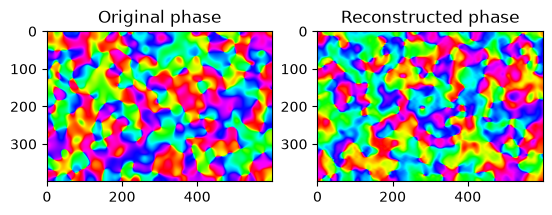

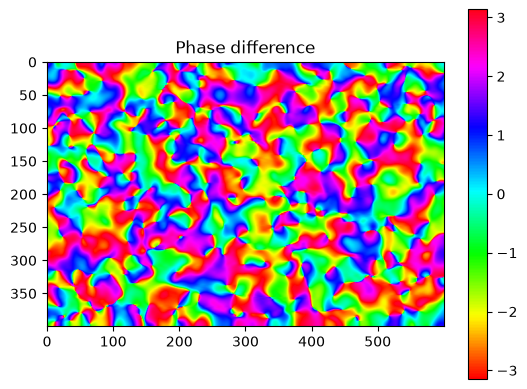

In [52]:
## Get the field after the second length
tempIFT = np.fft.ifft2(np.fft.ifftshift(Fh3))
finalField = tempIFT[0:Ny,0:Nx]

## Display the target phase map and the generated one
plt.figure()
plt.subplot(121)
plt.imshow(np.angle(image_sig),cmap=cm.hsv);
plt.title('Original phase')
plt.subplot(122)
plt.imshow(np.angle(finalField),cmap=cm.hsv);
plt.title('Reconstructed phase')

plt.figure()
plt.imshow(np.angle(image_sig/finalField),cmap=cm.hsv);
plt.title('Phase difference')
plt.colorbar()